# Car Price Prediction with Machine Learning
**CodeAlpha Data Science Internship — Task 3**

**Goal:** Predict the selling price of a used car (or two-wheeler) from its features:
brand, age, showroom price, kilometres driven, fuel type, seller type, transmission and
number of previous owners.

**Data:** [Car Price Prediction — Used Cars (Kaggle)](https://www.kaggle.com/datasets/vijayaadithyanvg/car-price-predictionused-cars),
listings from the Indian used-vehicle market. Prices are in **lakhs of rupees**
(1 lakh = ₹1,00,000).

**Steps:** load & clean → EDA → feature engineering → train & compare regression models →
evaluate → interpret → predict a new car.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/car data.csv")
# Some copies of this dataset use slightly different column names, so we standardise them.
df = df.rename(columns={"Kms_Driven": "Driven_kms", "Seller_Type": "Selling_type"})
print("Shape:", df.shape)
df.head()

Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [4]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
for col in ["Fuel_Type", "Selling_type", "Transmission", "Owner"]:
    print(f"\n{col}:\n{df[col].value_counts().to_string()}")

Missing values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Duplicate rows: 2

Fuel_Type:
Fuel_Type
Petrol    239
Diesel     60
CNG         2

Selling_type:
Selling_type
Dealer        195
Individual    106

Transmission:
Transmission
Manual       261
Automatic     40

Owner:
Owner
0    290
1     10
3      1


In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df.describe().round(2)

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.00,299.00,299.00,299.00,299.00
mean,2013.62,4.59,7.54,36916.75,0.04
std,2.90,4.98,8.57,39015.17,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.85,1.20,15000.00,0.00
50%,2014.00,3.51,6.10,32000.00,0.00
75%,2016.00,6.00,9.84,48883.50,0.00
max,2018.00,35.00,92.60,500000.00,3.00


**Notes**
- No missing values. Duplicate rows (if any) are removed above.
- `Selling_Price` and `Present_Price` (today's showroom price of the same model) are in lakhs.
- The data mixes **cars and two-wheelers** (e.g. *Royal Enfield*, *Bajaj Pulsar*).

## 2. Feature engineering
- **Car_Age**: how old the vehicle is. Calculated from the most recent year in the data,
  which is when the listings were collected.
- **Brand**: taken from `Car_Name`. Many names are just the model (e.g. *city*, *swift*),
  so we map models to their maker. Brand is a stand-in for **brand goodwill**.
- **Vehicle_Type**: car or two-wheeler.
- **Depreciation** (for EDA only): how much of the showroom price has been lost.

In [6]:
MODEL_TO_BRAND = {
    # Maruti Suzuki
    "ritz": "Maruti", "sx4": "Maruti", "ciaz": "Maruti", "wagon r": "Maruti", "swift": "Maruti",
    "vitara brezza": "Maruti", "s cross": "Maruti", "alto 800": "Maruti", "ertiga": "Maruti",
    "dzire": "Maruti", "alto k10": "Maruti", "ignis": "Maruti", "800": "Maruti", "baleno": "Maruti",
    "omni": "Maruti", "s-cross": "Maruti",
    # Toyota
    "fortuner": "Toyota", "corolla altis": "Toyota", "corolla": "Toyota", "innova": "Toyota",
    "etios cross": "Toyota", "etios g": "Toyota", "etios liva": "Toyota", "etios gd": "Toyota",
    "camry": "Toyota", "land cruiser": "Toyota",
    # Honda (cars)
    "city": "Honda", "brio": "Honda", "amaze": "Honda", "jazz": "Honda",
    # Hyundai
    "i20": "Hyundai", "grand i10": "Hyundai", "i10": "Hyundai", "eon": "Hyundai",
    "xcent": "Hyundai", "elantra": "Hyundai", "creta": "Hyundai", "verna": "Hyundai",
}
TWO_WHEELER_BRANDS = ["royal enfield", "bajaj", "hero", "honda", "yamaha", "tvs", "ktm",
                      "suzuki", "um", "hyosung", "mahindra mojo", "activa", "harley", "kawasaki"]

def get_brand(name):
    n = str(name).strip().lower()
    if n in MODEL_TO_BRAND:
        return MODEL_TO_BRAND[n], "Car"
    for b in TWO_WHEELER_BRANDS:
        if n.startswith(b):
            brand = "Honda" if b == "activa" else ("Mahindra" if b == "mahindra mojo" else b.title())
            return brand, "Two-wheeler"
    return n.split()[0].title(), "Car"

df[["Brand", "Vehicle_Type"]] = df["Car_Name"].apply(lambda n: pd.Series(get_brand(n)))
REF_YEAR = df["Year"].max() + 1
df["Car_Age"] = REF_YEAR - df["Year"]
df["Depreciation_%"] = (1 - df["Selling_Price"] / df["Present_Price"]) * 100
# Prices and kilometres are very skewed, so we also keep their logs.
# A log-log linear model says "price falls by a percentage", which is how depreciation works.
df["Log_Present_Price"] = np.log(df["Present_Price"])
df["Log_Driven_kms"] = np.log(df["Driven_kms"])

print("Reference year:", REF_YEAR)
print(df["Vehicle_Type"].value_counts().to_string())
print("\nBrands:\n", df["Brand"].value_counts().to_string())

Reference year: 2019
Vehicle_Type
Car            198
Two-wheeler    101

Brands:
 Brand
Honda            70
Hyundai          50
Maruti           49
Toyota           49
Bajaj            25
Royal Enfield    17
Hero             15
Yamaha            8
Tvs               8
Ktm               4
Um                1
Hyosung           1
Mahindra          1
Suzuki            1


## 3. Exploratory data analysis

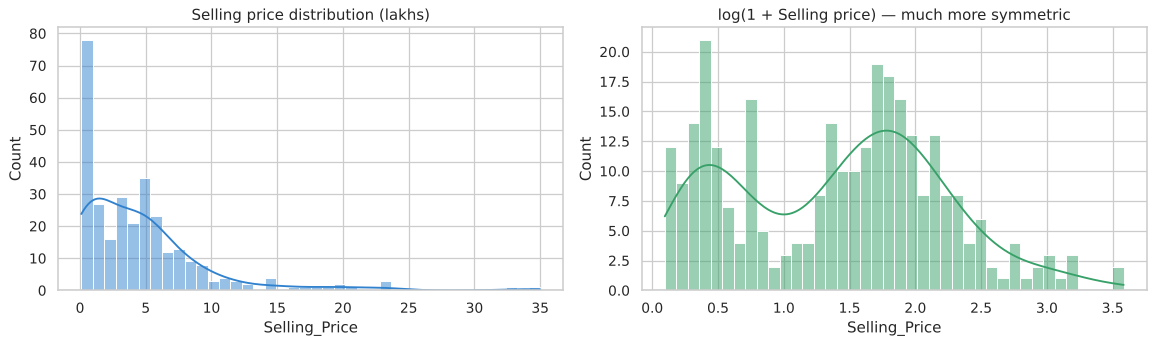

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Selling_Price"], bins=40, kde=True, ax=axes[0], color="#3182CE")
axes[0].set_title("Selling price distribution (lakhs)")
sns.histplot(np.log1p(df["Selling_Price"]), bins=40, kde=True, ax=axes[1], color="#38A169")
axes[1].set_title("log(1 + Selling price) — much more symmetric")
plt.tight_layout()
fig.savefig("images/price_distribution.png", dpi=120, bbox_inches="tight")

The price is heavily **right-skewed**: most vehicles are cheap and a few are very expensive.
Linear models work better on the log of the price, so we will try that.

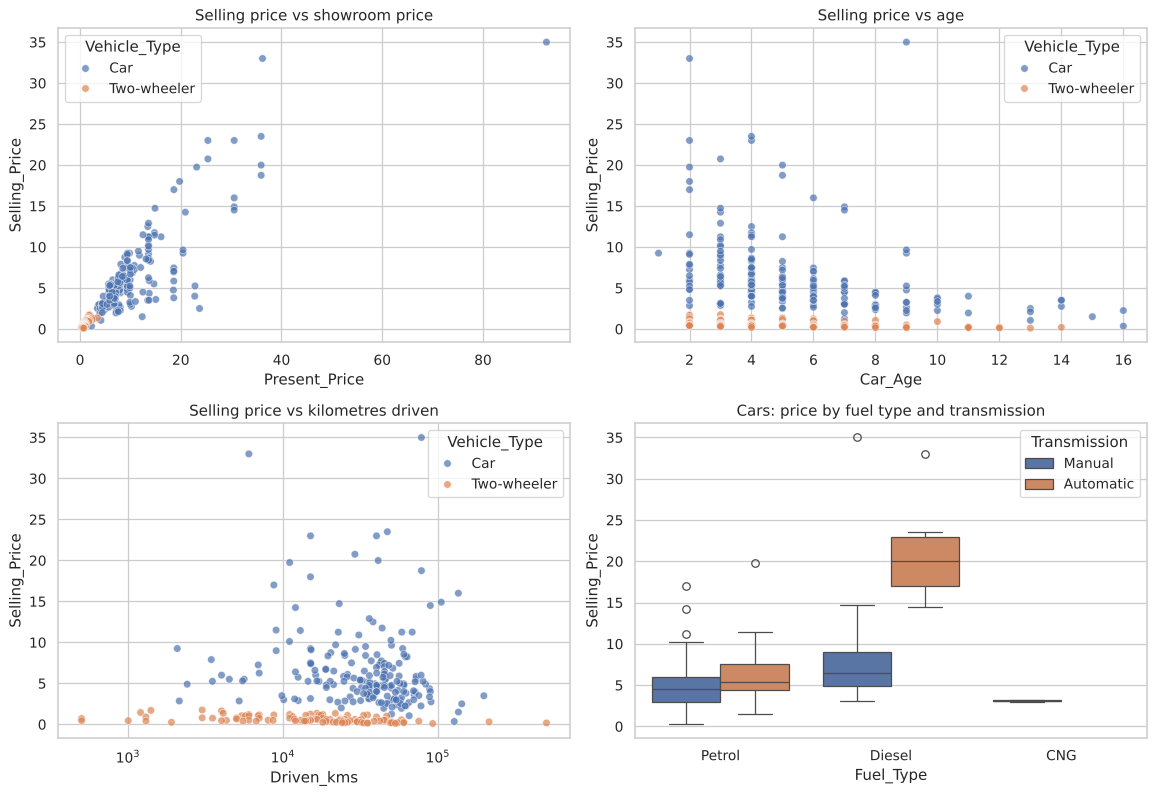

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price", hue="Vehicle_Type", ax=axes[0, 0], alpha=0.7)
axes[0, 0].set_title("Selling price vs showroom price")
sns.scatterplot(data=df, x="Car_Age", y="Selling_Price", hue="Vehicle_Type", ax=axes[0, 1], alpha=0.7)
axes[0, 1].set_title("Selling price vs age")
sns.scatterplot(data=df, x="Driven_kms", y="Selling_Price", hue="Vehicle_Type", ax=axes[1, 0], alpha=0.7)
axes[1, 0].set_title("Selling price vs kilometres driven")
axes[1, 0].set_xscale("log")
sns.boxplot(data=df[df["Vehicle_Type"] == "Car"], x="Fuel_Type", y="Selling_Price", hue="Transmission", ax=axes[1, 1])
axes[1, 1].set_title("Cars: price by fuel type and transmission")
plt.tight_layout()
fig.savefig("images/eda_relationships.png", dpi=120, bbox_inches="tight")

In [9]:
cars = df[df["Vehicle_Type"] == "Car"]
brand_stats = cars.groupby("Brand").agg(
    Listings=("Selling_Price", "size"),
    Avg_Selling_Price=("Selling_Price", "mean"),
    Avg_Depreciation_pct=("Depreciation_%", "mean"),
).sort_values("Avg_Selling_Price", ascending=False)
brand_stats.round(2)

,Listings,Avg_Selling_Price,Avg_Depreciation_pct
Brand,,,
Toyota,49,10.16,47.99
Honda,50,6.21,33.55
Hyundai,50,5.48,29.27
Maruti,49,4.59,36.38


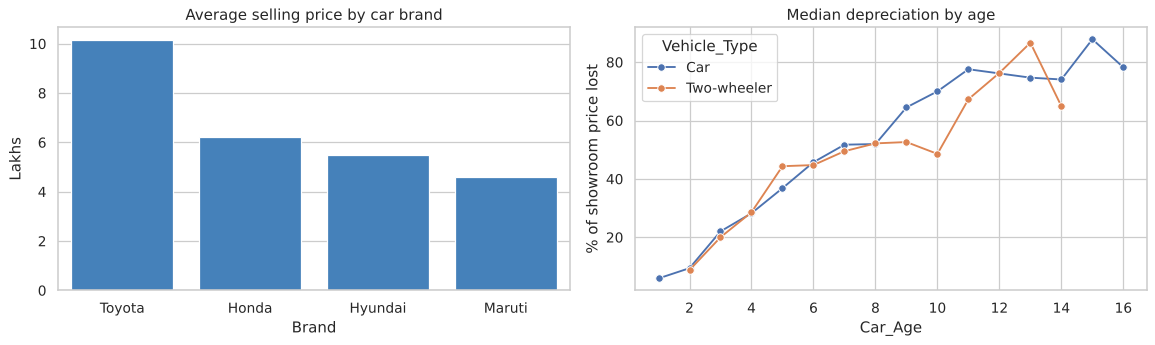

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=cars, x="Brand", y="Selling_Price", order=brand_stats.index, ax=axes[0], color="#3182CE", errorbar=None)
axes[0].set_title("Average selling price by car brand")
axes[0].set_ylabel("Lakhs")
age_dep = df.groupby(["Car_Age", "Vehicle_Type"])["Depreciation_%"].median().reset_index()
sns.lineplot(data=age_dep, x="Car_Age", y="Depreciation_%", hue="Vehicle_Type", marker="o", ax=axes[1])
axes[1].set_title("Median depreciation by age")
axes[1].set_ylabel("% of showroom price lost")
plt.tight_layout()
fig.savefig("images/brand_depreciation.png", dpi=120, bbox_inches="tight")

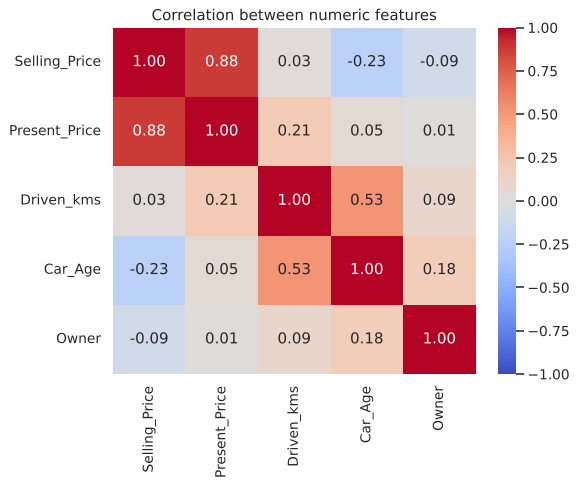

In [11]:
num_cols = ["Selling_Price", "Present_Price", "Driven_kms", "Car_Age", "Owner"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation between numeric features")
plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight")

## 4. Prepare data for modelling
- **Features:** log(Present_Price), log(Driven_kms), Car_Age, Owner, Fuel_Type, Selling_type,
  Transmission, Vehicle_Type, Brand. Using logs stops a few very expensive or very high-mileage
  vehicles (e.g. a ₹92-lakh Land Cruiser, a 5,00,000 km car) from dominating the linear models.
- `Car_Name` is dropped: it has too many unique values, and the useful part of it is
  already in `Brand` and `Vehicle_Type`.
- Categorical columns are one-hot encoded. Numeric columns are scaled (needed by the linear models).
- 80% train / 20% test split.

In [12]:
numeric = ["Log_Present_Price", "Log_Driven_kms", "Car_Age", "Owner"]
categorical = ["Fuel_Type", "Selling_type", "Transmission", "Vehicle_Type", "Brand"]

X = df[numeric + categorical]
y = df["Selling_Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=3), categorical),
    ])

Train: (239, 9) | Test: (60, 9)


## 5. Train and compare models
Linear models predict **log(price)** (then convert back), because the price is skewed.
Tree models handle skew on their own.

In [13]:
def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear Regression": log_target(LinearRegression()),
    "Ridge Regression": log_target(Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                   max_depth=3, random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({
        "Model": name,
        "CV R² (train)": cv_r2.mean(),
        "Test R²": r2_score(y_test, pred),
        "Test MAE (lakhs)": mean_absolute_error(y_test, pred),
        "Test RMSE (lakhs)": np.sqrt(mean_squared_error(y_test, pred)),
    })

results = pd.DataFrame(rows).sort_values("CV R² (train)", ascending=False).reset_index(drop=True)
results.round(3)

,Model,CV R² (train),Test R²,Test MAE (lakhs),Test RMSE (lakhs)
0,Linear Regression,0.940,0.881,0.978,1.751
1,Ridge Regression,0.934,0.877,0.982,1.783
2,Gradient Boosting,0.894,0.735,1.156,2.614
3,Random Forest,0.894,0.509,1.451,3.559


We pick the best model by **cross-validated R²** on the training set, not by test score.
This keeps the test set as a fair, unseen check.

In [14]:
best_name = results.loc[0, "Model"]
best = fitted[best_name]
y_pred = best.predict(X_test)
print(f"Best model: {best_name}")
print(f"Test R²:   {r2_score(y_test, y_pred):.3f}  (share of price variation explained)")
print(f"Test MAE:  {mean_absolute_error(y_test, y_pred):.2f} lakhs  (average error)")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} lakhs")

Best model: Linear Regression
Test R²:   0.881  (share of price variation explained)
Test MAE:  0.98 lakhs  (average error)
Test RMSE: 1.75 lakhs


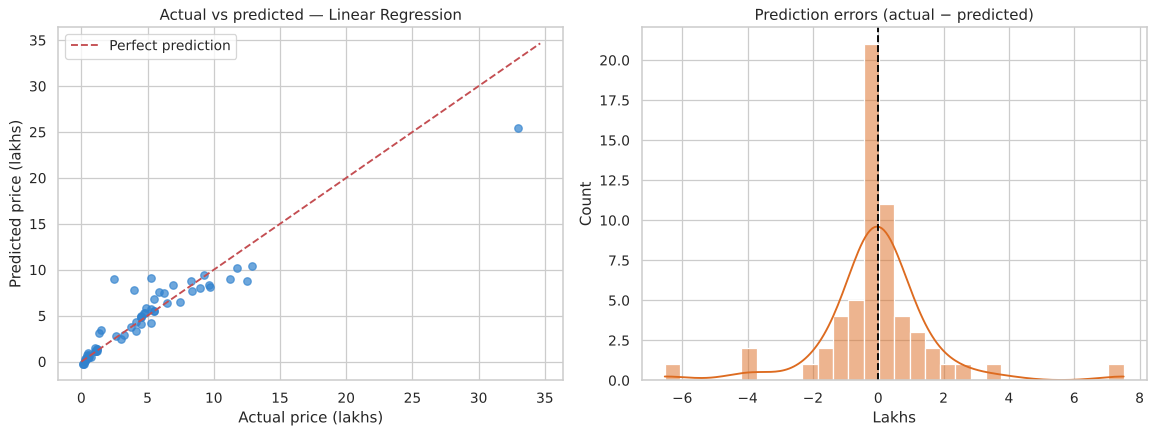

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, alpha=0.7, color="#3182CE")
lim = [0, max(y_test.max(), y_pred.max()) * 1.05]
axes[0].plot(lim, lim, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual price (lakhs)")
axes[0].set_ylabel("Predicted price (lakhs)")
axes[0].set_title(f"Actual vs predicted — {best_name}")
axes[0].legend()
residuals = y_test - y_pred
sns.histplot(residuals, bins=30, kde=True, ax=axes[1], color="#DD6B20")
axes[1].axvline(0, color="black", ls="--")
axes[1].set_title("Prediction errors (actual − predicted)")
axes[1].set_xlabel("Lakhs")
plt.tight_layout()
fig.savefig("images/actual_vs_predicted.png", dpi=120, bbox_inches="tight")

## 6. What drives the price?

Log_Present_Price         0.900
Car_Age                   0.072
Log_Driven_kms            0.013
Transmission_Manual       0.003
Transmission_Automatic    0.003
Selling_type_Dealer       0.002
Brand_Honda               0.001
Brand_Toyota              0.001
dtype: float64

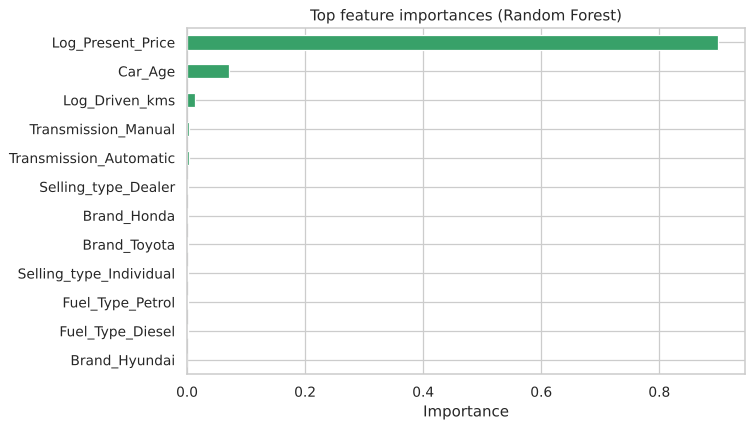

In [16]:
rf = fitted["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[1].replace("infrequent_sklearn", "Other (rare)") for f in feat_names]
importance = pd.Series(rf.named_steps["model"].feature_importances_, index=feat_names).sort_values(ascending=False)

importance.head(12).sort_values().plot(kind="barh", figsize=(8, 5), color="#38A169")
plt.title("Top feature importances (Random Forest)")
plt.xlabel("Importance")
plt.savefig("images/feature_importance.png", dpi=120, bbox_inches="tight")
importance.head(8).round(3)

In [17]:
lin = fitted["Linear Regression"]
coef_names = [f.split("__", 1)[1].replace("infrequent_sklearn", "Other (rare)") for f in lin.named_steps["prep"].get_feature_names_out()]
coefs = pd.Series(lin.named_steps["model"].regressor_.coef_, index=coef_names)
effect = ((np.exp(coefs) - 1) * 100).rename("Approx. % change in price")
print("Linear model on log(price): effect of a one-standard-deviation increase (numeric)")
print("or of having that category (categorical), all else equal.\n")
effect.reindex(effect.abs().sort_values(ascending=False).index).head(10).round(1)

Linear model on log(price): effect of a one-standard-deviation increase (numeric)
or of having that category (categorical), all else equal.



Log_Present_Price         126.4
Brand_Hero                 24.7
Brand_Ktm                 -23.8
Car_Age                   -16.9
Fuel_Type_Diesel           15.1
Fuel_Type_Other (rare)    -13.2
Brand_Bajaj                 9.0
Brand_Tvs                   7.8
Transmission_Automatic      7.8
Transmission_Manual        -7.2
Name: Approx. % change in price, dtype: float64

## 7. Predict the price of a new car

In [18]:
new_cars = pd.DataFrame([
    {"Present_Price": 9.85, "Driven_kms": 30000, "Car_Age": 3, "Owner": 0, "Fuel_Type": "Petrol",
     "Selling_type": "Dealer", "Transmission": "Manual", "Vehicle_Type": "Car", "Brand": "Maruti"},
    {"Present_Price": 30.6, "Driven_kms": 45000, "Car_Age": 5, "Owner": 0, "Fuel_Type": "Diesel",
     "Selling_type": "Dealer", "Transmission": "Automatic", "Vehicle_Type": "Car", "Brand": "Toyota"},
    {"Present_Price": 1.47, "Driven_kms": 15000, "Car_Age": 4, "Owner": 0, "Fuel_Type": "Petrol",
     "Selling_type": "Individual", "Transmission": "Manual", "Vehicle_Type": "Two-wheeler", "Brand": "Royal Enfield"},
])
new_cars["Log_Present_Price"] = np.log(new_cars["Present_Price"])
new_cars["Log_Driven_kms"] = np.log(new_cars["Driven_kms"])
new_cars["Predicted_Selling_Price (lakhs)"] = best.predict(new_cars).round(2)
new_cars.drop(columns=["Log_Present_Price", "Log_Driven_kms"])

,Present_Price,Driven_kms,Car_Age,Owner,Fuel_Type,Selling_type,Transmission,Vehicle_Type,Brand,Predicted_Selling_Price (lakhs)
0,9.85,30000,3,0,Petrol,Dealer,Manual,Car,Maruti,6.50
1,30.60,45000,5,0,Diesel,Dealer,Automatic,Car,Toyota,17.60
2,1.47,15000,4,0,Petrol,Individual,Manual,Two-wheeler,Royal Enfield,1.17


## 8. Conclusion
- **Best model: Linear Regression on log(price) with log features.** It has a cross-validated
  R² of about **0.94**, a test R² of about **0.88**, and an average error of about **₹1 lakh**.
  It beat Random Forest and Gradient Boosting here because the dataset is small (≈300 rows).
  Tree models also cannot predict prices above the highest price they saw in training.
  This hurts them on the few expensive cars in the test set, such as a ₹33-lakh Fortuner.
- **Showroom price (Present_Price) is by far the strongest driver.** It accounts for about
  90% of Random Forest importance. A vehicle's original value sets its resale value.
- **Age is the second driver.** Each extra year lowers the price by a fairly steady
  percentage. Cars and two-wheelers follow a similar curve: about half the value is gone after 7–8 years.
- **Diesel and automatic** vehicles sell for more, all else being equal. Kilometres driven,
  number of owners and seller type matter much less once age and showroom price are known.
- **Brand goodwill shows up in resale value.** Toyota cars sell for the most on average.
  Hyundai and Honda cars keep their value better (≈30–34% average depreciation) than
  Toyota (≈48%), whose listings are older on average.

**Real-world use:** a model like this can suggest a fair listing price for sellers, flag
overpriced listings for buyers, and help dealers value trade-ins quickly.

*Limitations:* small dataset, a few rare categories (CNG, 3 owners), and no data on
condition, location or variant. More data would improve accuracy.